In [1]:
# Importing modules
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

In [2]:
# Reading lipid data
df = pd.read_csv("lipid_data_original.tsv", sep="\t")

# Dataframe manipulation
new_df = df.T[0:]
new_df["Sample"] = new_df.index
new_df.rename({0: 'Class'}, axis=1, inplace=True)
new_df = new_df.reset_index(drop=True)
new_df.rename({idx:i for idx, i in enumerate(df["UHID"].to_numpy())}, axis=1, inplace=True)
lipid_df = new_df

# Reading clinical data
df = pd.read_csv("clinical_data_original.tsv", sep="\t")

# Dataframe manipulation
new_df = df.T[1:]
new_df["Sample"] = new_df.index
new_df = new_df.reset_index(drop=True)
new_df.rename({idx:i for idx, i in enumerate(df["UHID"].to_numpy())}, axis=1, inplace=True)
clinical_df = new_df

# Merging both data
new_df = lipid_df.merge(clinical_df, on="Sample")

In [3]:
# Combined data
new_df

,Class,Group,SM(14:0),SM(16:0),SM(18:0),SM(18:1),SM(20:0),SM(20:1),SM(22:0),SM(22:1),...,PA(20:0/20:4),PA(20:0/20:5),PA(20:0/22:4),PA(20:0/22:5),PA(20:0/22:6),Sample,Age,Sex,Weight,Height
0,Old,NAFL,26.0703061205,189.9963323224,36.2250074768,19.385379713,25.328027196,12.791147449,44.2738892019,42.4407210659,...,0.0335031604,,,,0.0280766812,105739272,38,2,98,162
1,Old,NAFL,11.5901749464,94.8621513548,13.5839615432,6.3347813435,10.5177505411,4.5388246754,15.9060584349,21.7778554913,...,,0.0145509378,,0.0275863337,0.006422594,105518892,27,1,62,163
2,Old,NAFL,23.9606206465,148.9690916127,17.8028600991,7.4565074307,16.2703591404,5.5445008288,33.5278465054,39.8066736547,...,,0.0534529006,0.0711684829,,,104335119,33,1,87,180
3,Old,NAFL,19.5065419229,197.7565762294,31.3251660908,15.4072225058,27.9966980445,13.7148416627,43.7232051801,46.0055135193,...,,0.0325761517,0.0258207787,0.0398033615,0.0443769126,105922031,50.0,1.0,85.3,173.0
4,Old,NAFL,15.4279992388,132.1034393763,17.6408931462,8.6308682571,14.7112427006,6.1379925058,29.2083981478,29.6483664063,...,0.0192611164,,0.0361480709,0.0149438878,0.0456836542,102497659,58,2,78,150
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,New,Healthy,4.6062578336,82.8777456035,10.6546232497,4.4965158045,9.1250879026,4.4913068058,13.780991646,17.4063743478,...,0.8425571936,NaN,0.8134964738,0.8914572878,3.5124873316,105698556,56,1,55,163
99,New,Healthy,0.7844600708,13.3131338117,1.5575756333,0.6910927026,1.4207680591,0.627926368,2.6014715343,3.140757541,...,NaN,NaN,0.3495479688,NaN,0.256716803,107246079,38,1,77,179
100,New,Healthy,22.6024048928,96.574540383,18.7542006217,10.8994983921,12.8901247711,5.8527548412,20.6016729016,26.0706030063,...,0.0580043628,0.0149222943,NaN,0.0293224113,NaN,NL31897,51.0,2.0,58.6,161.5
101,New,Healthy,11.3731793935,95.5599234527,17.1203582831,11.783598977,9.8943362817,7.4241081779,15.6450746078,23.0281834528,...,0.1036773839,0.0895254823,0.0023870616,0.0464236014,0.0359118907,NL49418,53.0,2.0,64.8,154.0


In [4]:
############################## Preprocessing ##############################

# Dropping non-numeric data
X = new_df.drop(["Class", "Group", "Sample"], axis=1)

# 1. Replace ' ' with NaN
X = X.replace(' ', np.nan)

# 2. Convert all columns to numeric
X = X.apply(pd.to_numeric, errors='coerce')

# 3. Removing features with >20% missing values
X = X.loc[:, X.isnull().mean() <= 0.20]

# 4. KNN imputation (filling missing values)
imputer = KNNImputer(n_neighbors=3)

# Final df after imputation
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
X["Samples"] = new_df["Sample"].to_numpy()
X["Class"] = new_df["Group"].to_numpy()
X["Batch"] = new_df["Class"].to_numpy()

# Shape after inputation and filtering
X.shape

(103, 870)

In [5]:
# Lipid data
X_lipid = X.drop(["Age","Sex","Weight","Height"], axis=1)

# Clinical data
X_clinical = X[["Samples", "Class", "Batch", "Age", "Sex", "Weight","Height"]]

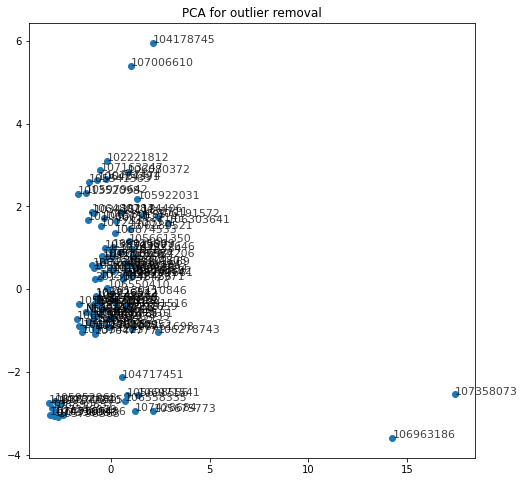

In [6]:
# PCA analysis for outliers identification

scaler = MinMaxScaler(feature_range=(0, 1))

scaled_X_lipid = scaler.fit_transform(X_lipid.drop(["Class", "Batch", "Samples"], axis=1))

sample_list = X_lipid["Samples"].to_numpy()

pca = PCA(n_components=2) 
X_pca = pca.fit_transform(scaled_X_lipid)
X_pca = pd.DataFrame(data=X_pca, columns=["PC1", "PC2"])

plt.figure(figsize=[8, 8])
plt.scatter(X_pca["PC1"], X_pca["PC2"],)
for i, label in enumerate(sample_list):
    plt.text(X_pca["PC1"][i], X_pca["PC2"][i], label, fontsize=11, alpha=0.75)
plt.title("PCA for outlier removal")
plt.show()

In [7]:
# Removing outliers ['107358073', '106963186', '104178745', '107006610']
X_lipid = X_lipid[X_lipid['Samples'].isin(['107358073', '106963186', '104178745', '107006610']) == False]

In [8]:
# Lipid data after outlier removal
X_lipid

,SM(14:0),SM(16:0),SM(18:0),SM(18:1),SM(20:0),SM(20:1),SM(22:0),SM(22:1),SM(24:0),SM(24:1),...,PS(18:0/20:4),PS(18:0/22:4),PS(18:1/18:1),PS(18:1/18:2),PS(18:1/20:4),PS(20:0/18:2),PS(20:0/20:4),Samples,Class,Batch
0,26.070306,189.996332,36.225007,19.385380,25.328027,12.791147,44.273889,42.440721,54.586892,123.727859,...,0.281631,0.012963,0.441891,0.156134,0.184993,0.328113,0.179792,105739272,NAFL,Old
1,11.590175,94.862151,13.583962,6.334781,10.517751,4.538825,15.906058,21.777855,15.718695,59.803610,...,1.060155,0.138498,0.269580,0.069172,0.024219,0.094890,0.039291,105518892,NAFL,Old
2,23.960621,148.969092,17.802860,7.456507,16.270359,5.544501,33.527847,39.806674,41.966176,108.556804,...,0.425400,0.057387,0.058831,0.048377,0.104254,0.201554,0.082750,104335119,NAFL,Old
3,19.506542,197.756576,31.325166,15.407223,27.996698,13.714842,43.723205,46.005514,48.707646,145.579299,...,0.967220,0.100734,0.271381,0.191456,0.199551,0.217702,0.190772,105922031,NAFL,Old
4,15.427999,132.103439,17.640893,8.630868,14.711243,6.137993,29.208398,29.648366,32.328560,91.637503,...,0.245838,0.039762,0.129429,0.116659,0.066346,0.019392,0.035739,102497659,NAFL,Old
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,4.606258,82.877746,10.654623,4.496516,9.125088,4.491307,13.780992,17.406374,11.734649,47.749706,...,4.400912,1.196131,8.052895,7.819517,1.909524,3.199196,3.355595,105698556,Healthy,New
99,0.784460,13.313134,1.557576,0.691093,1.420768,0.627926,2.601472,3.140758,2.008129,8.072753,...,0.593103,3.728990,3.236911,2.393848,1.800961,0.573409,0.208390,107246079,Healthy,New
100,22.602405,96.574540,18.754201,10.899498,12.890125,5.852755,20.601673,26.070603,17.283131,51.653346,...,0.603613,0.026839,0.293254,0.102729,0.123503,0.088066,0.087107,NL31897,Healthy,New
101,11.373179,95.559923,17.120358,11.783599,9.894336,7.424108,15.645075,23.028183,18.533436,67.981477,...,0.353559,0.067973,0.144486,0.178871,0.003177,0.218094,0.070152,NL49418,Healthy,New


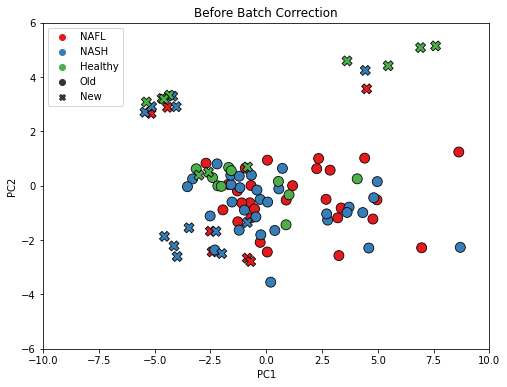

In [9]:
# PCA for observing batch effect

scaler = MinMaxScaler(feature_range=(0, 1))

pca = PCA(n_components=2)

scaled_data = scaler.fit_transform(X_lipid.drop(["Samples", "Class", "Batch"], axis=1))
batch_ = X_lipid["Batch"].to_numpy()
class_ = X_lipid["Class"].to_numpy()
sample_ = X_lipid["Samples"].to_numpy()

pca_data = pca.fit_transform(scaled_data)
pca_data = pd.DataFrame(pca_data, columns=["PC1", "PC2"])
pca_data["Samples"] = X_lipid["Samples"].to_numpy()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pca_data["PC1"],y=pca_data["PC2"], hue=class_, style=batch_, s=100, palette='Set1', edgecolor='k')
plt.xlim(-10, 10)
plt.ylim(-6, 6)
plt.title("Before Batch Correction")
plt.show()

In [10]:
# Saving imputed data for batch correction using MetaboAnalyst
X_lipid["Order"] = np.arange(1, 100)
X_lipid = X_lipid[X_lipid.columns[-4:].tolist() + X_lipid.columns[:-4].tolist()]
X_lipid = X_lipid.T
X_lipid.to_csv("lipid_data_inputed.csv", quoting=False, header=False)

### Batch correction using [MetaboAnalyst](https://www.metaboanalyst.ca/MetaboAnalyst/upload/BatchUpload.xhtml)

1. Select: Upload a single merged file
2. Data format: Sample in columns
3. Correction method: automated (default)
4. Evaluation target: Samples
5. Missing value estimation: LoDs (1/5 of the minimum)
6. Choose lipid_data_inputed.csv 
7. Click on upload
8. Download the batch corrected data table and all the plots once the analysis is completed

In [11]:
# Reading batch corrected lipid data
X_lipid = pd.read_csv("MetaboAnalyst_batch_data.csv")

sample = [i.replace("X", "") for i in X_lipid["NAME"].to_numpy()]
sample = [i.replace(".", "-") for i in sample]

X_lipid = X_lipid.rename(columns={'NAME': 'Samples', 'CLASS': 'Class', 'Dataset':'Batch'})
X_lipid["Samples"] = sample

# Lipid data after batch correction
X_lipid

,Samples,Class,Batch,SM(14:0),SM(16:0),SM(18:0),SM(18:1),SM(20:0),SM(20:1),SM(22:0),...,PS(18:0/18:1),PS(18:0/18:2),PS(18:0/20:3),PS(18:0/20:4),PS(18:0/22:4),PS(18:1/18:1),PS(18:1/18:2),PS(18:1/20:4),PS(20:0/18:2),PS(20:0/20:4)
0,105739272,NAFL,Old,26.989722,196.027582,37.872445,20.276172,26.450469,13.324297,46.027485,...,1.376940,1.763159,0.326393,1.274375,0.495065,0.470311,0.407940,1.930021,0.155687,0.769737
1,105518892,NAFL,Old,10.896242,77.525818,8.597803,3.957559,7.899167,3.327576,13.115463,...,1.426377,0.903485,0.365041,0.000000,1.297644,1.150008,0.043654,2.612604,0.689758,0.904814
2,104335119,NAFL,Old,26.103887,169.730733,23.540229,10.390772,19.797457,7.202502,38.391553,...,2.354496,3.578012,0.733617,3.111520,0.574830,0.000000,0.645843,2.665137,0.000000,0.961331
3,105922031,NAFL,Old,17.704452,173.767049,25.699900,12.684206,24.434816,12.058804,38.768607,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.049496,0.000000
4,102497659,NAFL,Old,14.638952,119.175583,14.972087,7.394331,12.955871,5.328155,26.708512,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,105698556,Healthy,New,1.511591,48.434856,2.357593,0.380969,3.773445,1.991100,6.111425,...,0.000000,0.000000,0.982859,0.000000,0.000000,6.470920,5.091736,0.000000,3.164355,0.000000
95,107246079,Healthy,New,4.725672,51.586076,9.456663,4.616123,7.175051,3.317921,11.834400,...,18.929201,23.678633,4.658517,10.485827,12.568877,7.489801,7.470421,28.712052,1.659252,9.651507
96,NL31897,Healthy,New,25.597787,125.421362,23.922123,13.426892,17.017407,7.777756,27.670614,...,17.293225,22.527882,4.652937,9.526395,9.029490,4.910980,5.100203,26.997265,1.544231,9.526393
97,NL49418,Healthy,New,14.409877,125.603826,22.606245,14.459470,14.192818,9.427957,22.901910,...,16.894367,22.679163,4.544266,9.405933,9.062113,4.746787,5.216114,26.898003,1.654955,9.520513


In [12]:
############################## Preprocessing ##############################

# Replacing 0 with NA
X_lat_na = X_lipid.drop(["Samples","Batch", "Class"], axis =1)
X_lat_na = X_lat_na.replace(0, np.nan)

# KNN imputation
imputer = KNNImputer(n_neighbors=3)
cols = X_lat_na.columns.to_numpy()
X_lat_imputed = pd.DataFrame(imputer.fit_transform(X_lat_na), columns=cols)
X_lat_imputed[["Samples","Batch", "Class"]] = X_lipid[["Samples","Batch", "Class"]]
X_lipid = X_lat_imputed

# Final imputed lipid data
X_lipid

,SM(14:0),SM(16:0),SM(18:0),SM(18:1),SM(20:0),SM(20:1),SM(22:0),SM(22:1),SM(24:0),SM(24:1),...,PS(18:0/20:4),PS(18:0/22:4),PS(18:1/18:1),PS(18:1/18:2),PS(18:1/20:4),PS(20:0/18:2),PS(20:0/20:4),Samples,Batch,Class
0,26.989722,196.027582,37.872445,20.276172,26.450469,13.324297,46.027485,43.970457,56.919954,130.259090,...,1.274375,0.495065,0.470311,0.407940,1.930021,0.155687,0.769737,105739272,Old,NAFL
1,10.896242,77.525818,8.597803,3.957559,7.899167,3.327576,13.115463,18.097020,13.213840,48.814360,...,2.790527,1.297644,1.150008,0.043654,2.612604,0.689758,0.904814,105518892,Old,NAFL
2,26.103887,169.730733,23.540229,10.390772,19.797457,7.202502,38.391553,44.681939,47.877840,126.986214,...,3.111520,0.574830,1.294544,0.645843,2.665137,0.860851,0.961331,104335119,Old,NAFL
3,17.704452,173.767049,25.699900,12.684206,24.434816,12.058804,38.768607,40.873285,41.940508,126.517328,...,2.157212,0.631748,0.860238,0.623025,2.617030,0.049496,0.991134,105922031,Old,NAFL
4,14.638952,119.175583,14.972087,7.394331,12.955871,5.328155,26.708512,27.039142,28.582336,81.929263,...,2.157212,1.447211,1.190926,1.008502,4.845618,0.194466,1.751368,102497659,Old,NAFL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,1.511591,48.434856,2.357593,0.380969,3.773445,1.991100,6.111425,9.785004,1.289347,18.475955,...,31.498448,13.434001,6.470920,5.091736,30.371837,3.164355,11.238667,105698556,New,Healthy
95,4.725672,51.586076,9.456663,4.616123,7.175051,3.317921,11.834400,11.502826,16.298648,43.139289,...,10.485827,12.568877,7.489801,7.470421,28.712052,1.659252,9.651507,107246079,New,Healthy
96,25.597787,125.421362,23.922123,13.426892,17.017407,7.777756,27.670614,32.200739,29.104900,78.513364,...,9.526395,9.029490,4.910980,5.100203,26.997265,1.544231,9.526393,NL31897,New,Healthy
97,14.409877,125.603826,22.606245,14.459470,14.192818,9.427957,22.901910,29.403749,30.548576,95.585428,...,9.405933,9.062113,4.746787,5.216114,26.898003,1.654955,9.520513,NL49418,New,Healthy


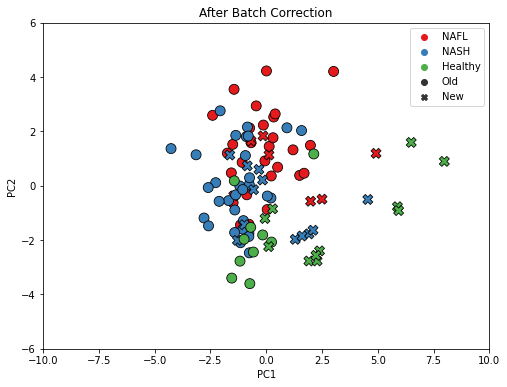

In [13]:
# PCA after batch correction + imputation

scaler = MinMaxScaler(feature_range=(0, 1))

pca = PCA(n_components=2)

scaled_data = scaler.fit_transform(X_lipid.drop(["Samples", "Class", "Batch"], axis=1))
batch_ = X_lipid["Batch"].to_numpy()
class_ = X_lipid["Class"].to_numpy()
sample_ = X_lipid["Samples"].to_numpy()

pca_data = pca.fit_transform(scaled_data)
pca_data = pd.DataFrame(pca_data, columns=["PC1", "PC2"])
pca_data["Samples"] = X_lipid["Samples"].to_numpy()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pca_data["PC1"],y=pca_data["PC2"], hue=class_, style=batch_, s=100, palette='Set1', edgecolor='k')
plt.xlim(-10, 10)
plt.ylim(-6, 6)
plt.title("After Batch Correction")
plt.show()

In [14]:
# Saving final data for ML
X_lipid.to_csv("final_data.tsv", quoting=False, index=False)